In [1]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.circuit import QuantumCircuit
from qiskit import transpile

qc = QuantumCircuit(1, 1)
qc.x(0)
qc.measure(0, 0)
    
# Build noise model
noise_model = NoiseModel()
error = depolarizing_error(0.75, 1)
noise_model.add_all_qubit_quantum_error(
    error, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# Noiseless
sim_ideal = AerSimulator()
result_ideal = sim_ideal.run(transpile(qc, sim_ideal), shots=1024).result()
print("Noiseless     :", result_ideal.get_counts())

# Noisy
sim_noisy = AerSimulator(noise_model=noise_model)
result_noisy = sim_noisy.run(transpile(qc, sim_noisy), shots=1024).result()
print("Noisy p=0.75  :", result_noisy.get_counts())

Noiseless     : {'1': 1024}
Noisy p=0.75  : {'1': 628, '0': 396}


In [2]:
sim_check = AerSimulator()
qc_t = transpile(qc, sim_check)
print("Basis gates used:", qc_t.count_ops())

Basis gates used: OrderedDict({'x': 1, 'measure': 1})


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json

from qiskit.circuit import QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

All imports OK ✅


In [74]:
p_true = 0.1

class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)

class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k

problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")

Problem defined ✅


In [48]:
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# Build noise model
noise_model_test = NoiseModel()
error_1q = depolarizing_error(0.75, 1)
noise_model_test.add_all_qubit_quantum_error(
    error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# ── Clean baseline ──
sampler_clean = AerSampler(
    run_options={"shots": 1024}         # shots in run_options
)
iae_clean = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_clean
)
result_clean = iae_clean.estimate(problem)
print(f"p=0.00 | Estimate: {result_clean.estimation:.4f} | Queries: {result_clean.num_oracle_queries}")

# ── Noisy run ──
sampler_noisy = AerSampler(
    backend_options={"noise_model": noise_model_test},  # ✅ noise in backend_options
    run_options={"shots": 1024}                         # ✅ shots in run_options
)
iae_noisy = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_noisy
)
result_noisy = iae_noisy.estimate(problem)
print(f"p=0.75 | Estimate: {result_noisy.estimation:.4f} | Queries: {result_noisy.num_oracle_queries}")

# ── Difference check ──
diff = abs(result_clean.estimation - result_noisy.estimation)
print(f"\nDifference: {diff:.4f}")
if diff < 0.01:
    print("❌ Noise is NOT being applied!")
else:
    print("✅ Noise IS affecting the estimate!")

p=0.00 | Estimate: 0.3021 | Queries: 7168
p=0.75 | Estimate: 0.4936 | Queries: 3072

Difference: 0.1915
✅ Noise IS affecting the estimate!


In [ ]:
import numpy as np
from joblib import Parallel, delayed
from scipy.special import expit
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════
SHOT_VALUES    = [2**10]
N_REPEATS      = 20
N_JOBS         = 18
epsilon_values = np.linspace(0.0001, 0.1, 100).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.4, 25).tolist()

Z_95 = 1.96

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {len(epsilon_values) * len(noise_levels)}")
print(f"Total IQAE runs   : {len(epsilon_values) * len(noise_levels) * N_REPEATS} per shot count")
print(f"Shot values       : {SHOT_VALUES}")
print(f"Running on        : {N_JOBS} parallel threads")

# ══════════════════════════════════════════════════════════════════════════════
# WILSON SCORE INTERVAL
#
#   For k successes out of N Bernoulli trials at confidence z:
#
#        p_hat = k / N
#
#        centre = (p_hat + z²/2N) / (1 + z²/N)
#
#        half_width = z * sqrt( p_hat(1-p_hat)/N + z²/4N² )
#                     ─────────────────────────────────────
#                                 1 + z²/N
#
#   Returns (success_rate, lower_CI, upper_CI, half_width)
#   Stays bounded in [0,1] even for k=0 or k=N  ✅
# ══════════════════════════════════════════════════════════════════════════════
def wilson_score(k, n, z=Z_95):
    """
    k : number of successes
    n : total trials
    z : z-score (default 1.96 → 95% CI)
    Returns: (p_hat, lower, upper, half_width)
    """
    p_hat      = k / n
    z2n        = z ** 2 / n
    centre     = (p_hat + z2n / 2) / (1 + z2n)
    half_width = (z * np.sqrt(p_hat * (1 - p_hat) / n + z2n / 4)) / (1 + z2n)
    lower      = np.clip(centre - half_width, 0.0, 1.0)
    upper      = np.clip(centre + half_width, 0.0, 1.0)
    return float(p_hat), float(lower), float(upper), float(half_width)

# ══════════════════════════════════════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════════════════════════════════════
# All standard single-qubit basis/native gates Qiskit might emit
SINGLE_QUBIT_GATES = [
    'id', 'x', 'y', 'z', 'h', 's', 'sdg', 't', 'tdg',
    'sx', 'sxdg', 'rx', 'ry', 'rz',
    'u', 'u1', 'u2', 'u3', 'p'
]

def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        p_1q = min(p_depol, 0.75)
        error_1q = depolarizing_error(p_1q, 1)

        noise_model = NoiseModel()
        noise_model.add_all_qubit_quantum_error(error_1q, SINGLE_QUBIT_GATES)

        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler

# ══════════════════════════════════════════════════════════════════════════════
# SINGLE COMBINATION — runs in parallel
#
#   Each repeat is a Bernoulli trial:
#       success (1) : |estimate - p_true| <= epsilon
#       failure (0) : |estimate - p_true| >  epsilon
#
#   Returns the success rate + Wilson CI for the (eps, noise) point
# ══════════════════════════════════════════════════════════════════════════════
def run_combination(p_noise, eps, p_true, n_repeats, n_shots):
    sampler  = build_noisy_sampler(p_noise, n_shots)
    outcomes = []

    for _ in range(n_repeats):
        try:
            iae = IterativeAmplitudeEstimation(
                epsilon_target = eps,
                alpha          = 0.05,
                sampler        = sampler,
            )
            result  = iae.estimate(problem)
            success = 1 if abs(result.estimation - p_true) <= eps else 0
            outcomes.append(success)
        except:
            outcomes.append(0)

    k                           = sum(outcomes)
    p_hat, lower, upper, half_w = wilson_score(k, n_repeats)

    return {
        "epsilon"     : eps,
        "noise"       : p_noise,
        "success_rate": p_hat,
        "wilson_lower": lower,
        "wilson_upper": upper,
        "wilson_hw"   : half_w,
        "k"           : k,
        "n"           : n_repeats,
    }

# ══════════════════════════════════════════════════════════════════════════════
# MAIN SIMULATION LOOP — iterates over all shot counts
# Results stored in `all_sweep_results` for Cell 2 to consume
# ══════════════════════════════════════════════════════════════════════════════
combinations     = [(p_noise, eps) for p_noise in noise_levels for eps in epsilon_values]
all_sweep_results = {}   # { n_shots : [list of result dicts] }

for n_shots in SHOT_VALUES:

    print(f"\n{'▓'*75}")
    print(f"  🚀  Running sweep  —  SHOTS = {n_shots}")
    print(f"{'▓'*75}")

    sweep_results = Parallel(n_jobs=N_JOBS, verbose=10)(
        delayed(run_combination)(p_noise, eps, p_true, N_REPEATS, n_shots)
        for p_noise, eps in combinations
    )

    all_sweep_results[n_shots] = sweep_results
    print(f"\n  ✅ Sweep complete — {len(sweep_results)} combinations stored")

print(f"\n{'═'*75}")
print(f"  ✅ ALL SWEEPS COMPLETE — results stored in `all_sweep_results`")
print(f"  Keys: {list(all_sweep_results.keys())}")
print(f"{'═'*75}")

Epsilon values    : 100 | 0.000100 → 0.100000
Noise levels      : 26  | 0.0000 → 0.4000
Total combinations: 2600
Total IQAE runs   : 52000 per shot count
Shot values       : [1024]
Running on        : 18 parallel threads

▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  🚀  Running sweep  —  SHOTS = 1024
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓


[Parallel(n_jobs=18)]: Using backend LokyBackend with 18 concurrent workers.
[Parallel(n_jobs=18)]: Done   5 tasks      | elapsed:   17.9s
[Parallel(n_jobs=18)]: Done  14 tasks      | elapsed:   18.3s
[Parallel(n_jobs=18)]: Done  25 tasks      | elapsed:   27.0s
[Parallel(n_jobs=18)]: Done  36 tasks      | elapsed:   31.2s
[Parallel(n_jobs=18)]: Done  49 tasks      | elapsed:   36.5s
[Parallel(n_jobs=18)]: Done  62 tasks      | elapsed:   38.7s
[Parallel(n_jobs=18)]: Done  77 tasks      | elapsed:   44.3s
[Parallel(n_jobs=18)]: Done  92 tasks      | elapsed:   52.6s
[Parallel(n_jobs=18)]: Done 109 tasks      | elapsed:  1.1min
[Parallel(n_jobs=18)]: Done 126 tasks      | elapsed:  1.2min
[Parallel(n_jobs=18)]: Done 145 tasks      | elapsed:  1.2min
[Parallel(n_jobs=18)]: Done 164 tasks      | elapsed:  1.3min
[Parallel(n_jobs=18)]: Done 185 tasks      | elapsed:  1.3min
[Parallel(n_jobs=18)]: Done 206 tasks      | elapsed:  1.4min
[Parallel(n_jobs=18)]: Done 229 tasks      | elapsed:  

KeyboardInterrupt: 


▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  📊  Analysing  —  SHOTS = 1024
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  📍 Boundary points: 81 kept, 19 dropped (|ŝ-0.5| > 0.1)
  📏 Median transition width (noise): 0.0665  (wider ⇒ noisier/fuzzier boundary)
    Linear:  m=1.5049  c=0.0692  R²=0.8271  RMSE=0.019820
    Full (global search, K∈(0.1, 30.0)):  m=1.1757  c=0.0798  B=0.3871  K=5.6881  (period≈1.594 octaves)  R²=0.9135  RMSE=0.014021


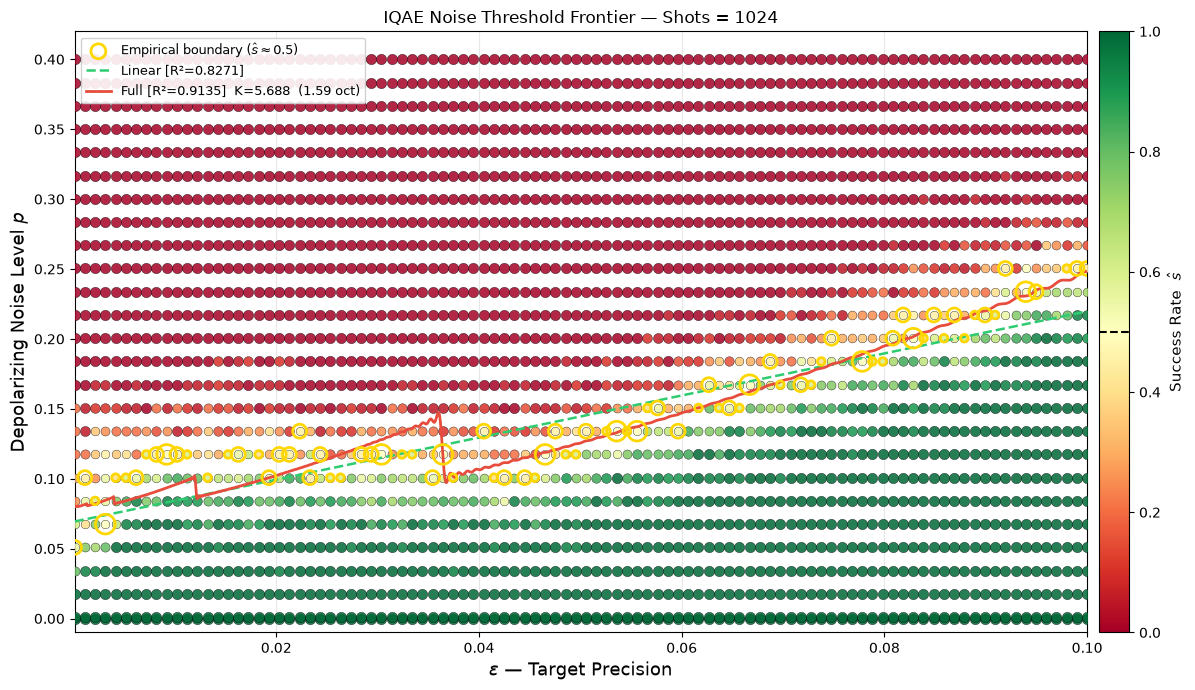


══════════════════════════════════════════════════════════════════════════════════════════
  FULL MODEL SUMMARY  |  h(ε) = m·ε + c - B·ε·Σsin(nK ln ε)/n
══════════════════════════════════════════════════════════════════════════════════════════
     Shots        R²        RMSE           m           c           B           K   period(oct)
  --------------------------------------------------------------------------------------
      1024    0.9135    0.014021      1.1757      0.0798      0.3871      5.6881         1.594
══════════════════════════════════════════════════════════════════════════════════════════


In [73]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit, differential_evolution

# ══════════════════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════
ACCEPTANCE_BAND = 0.1
N_TERMS         = 50     # Fourier truncation for sawtooth sharpness

# ══════════════════════════════════════════════════════════════════════════════
# EMPIRICAL BOUNDARY EXTRACTOR (+ transition-width diagnostic)
# ══════════════════════════════════════════════════════════════════════════════
def extract_empirical_boundary(sweep_results, verbose=True):
    eps_boundary, pstar_boundary, srate_boundary = [], [], []
    transition_widths = []   # diagnostic: how "sharp" is the sigmoid at each eps

    unique_epsilons = sorted(set(e["epsilon"] for e in sweep_results))

    for eps in unique_epsilons:
        pts = [e for e in sweep_results if e["epsilon"] == eps]
        pts.sort(key=lambda x: x["noise"])

        distances = [abs(p["success_rate"] - 0.5) for p in pts]
        idx_best  = int(np.argmin(distances))
        best_pt   = pts[idx_best]

        # diagnostic: noise range where success rate is between 0.1 and 0.9
        soft_band = [p["noise"] for p in pts if 0.1 <= p["success_rate"] <= 0.9]
        if len(soft_band) >= 2:
            transition_widths.append(max(soft_band) - min(soft_band))

        if distances[idx_best] > ACCEPTANCE_BAND:
            continue

        eps_boundary.append(eps)
        pstar_boundary.append(best_pt["noise"])
        srate_boundary.append(best_pt["success_rate"])

    n_total, n_kept = len(unique_epsilons), len(eps_boundary)
    if verbose:
        print(f"  📍 Boundary points: {n_kept} kept, "
              f"{n_total - n_kept} dropped (|ŝ-0.5| > {ACCEPTANCE_BAND})")
        if transition_widths:
            print(f"  📏 Median transition width (noise): "
                  f"{np.median(transition_widths):.4f}  "
                  f"(wider ⇒ noisier/fuzzier boundary)")

    return (np.array(eps_boundary), np.array(pstar_boundary),
            np.array(srate_boundary))

# ══════════════════════════════════════════════════════════════════════════════
# METRICS
# ══════════════════════════════════════════════════════════════════════════════
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot

def rmse_metric(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# ══════════════════════════════════════════════════════════════════════════════
# MODELS
#   Linear:      g(ε) = m·ε + c
#   Sawtooth:    f(ε) = -B·ε · Σ sin(n·K·ln ε)/n     n=1..N
#   Full:        h(ε) = g(ε) + f(ε)
#   K is left fully free — period = 2π/K in ln(ε), i.e. period_octaves = (2π/K)/ln2
# ══════════════════════════════════════════════════════════════════════════════
def linear_model(eps, m, c):
    return m * eps + c

def sawtooth_series(eps, K, N=N_TERMS):
    eps = np.clip(np.asarray(eps, dtype=float), 1e-10, np.inf)
    result = np.zeros_like(eps)
    for n in range(1, N + 1):
        result -= np.sin(n * K * np.log(eps)) / n
    return result

def full_model(eps, m, c, B, K):
    return m * eps + c + B * eps * sawtooth_series(eps, K)

def period_octaves(K):
    return (2.0 * np.pi / K) / np.log(2.0)

# ══════════════════════════════════════════════════════════════════════════════
# LINEAR FIT
# ══════════════════════════════════════════════════════════════════════════════
def fit_linear(eps_boundary, pstar_boundary, srate_boundary):
    weights   = 1.0 / (np.abs(srate_boundary - 0.5) + 0.01)
    fit_sigma = 1.0 / weights
    try:
        popt, pcov = curve_fit(
            linear_model, eps_boundary, pstar_boundary,
            p0=[1.0, 0.0], bounds=([0.0, -np.inf], [np.inf, np.inf]),
            sigma=fit_sigma, maxfev=20_000
        )
        perr   = np.sqrt(np.diag(pcov))
        y_pred = linear_model(eps_boundary, *popt)
        r2, rm = r_squared(pstar_boundary, y_pred), rmse_metric(pstar_boundary, y_pred)
        print(f"    Linear:  m={popt[0]:.4f}  c={popt[1]:.4f}  R²={r2:.4f}  RMSE={rm:.6f}")
        return {"popt": popt, "perr": perr, "r2": r2, "rmse": rm}
    except RuntimeError as exc:
        print(f"  ⚠ Linear fit failed: {exc}")
        return None

# ══════════════════════════════════════════════════════════════════════════════
# FULL MODEL FIT — global search over K via differential_evolution,
# then polish with curve_fit for proper uncertainty estimates (pcov).
# ══════════════════════════════════════════════════════════════════════════════
def fit_full_model(eps_boundary, pstar_boundary, srate_boundary,
                    K_bounds=(0.1, 30.0)):
    weights   = 1.0 / (np.abs(srate_boundary - 0.5) + 0.01)
    fit_sigma = 1.0 / weights

    m_span = max(pstar_boundary.max() - pstar_boundary.min(), 1e-3) / \
             max(eps_boundary.max() - eps_boundary.min(), 1e-6)
    c_span = max(abs(pstar_boundary.min()), abs(pstar_boundary.max()), 1.0)
    B_span = max(pstar_boundary.max() - pstar_boundary.min(), 1e-3)

    def objective(params):
        m, c, B, K = params
        y_pred = full_model(eps_boundary, m, c, B, K)
        return np.sum(((pstar_boundary - y_pred) / fit_sigma) ** 2)

    result = differential_evolution(
        objective,
        bounds=[(0.0, 5 * m_span), (-c_span, c_span),
                (0.0, 5 * B_span), K_bounds],
        seed=42, maxiter=3000, tol=1e-12, polish=True,
        mutation=(0.5, 1.5), recombination=0.7
    )

    m0, c0, B0, K0 = result.x

    # ── Polish with curve_fit to get proper covariance / uncertainties ───────
    try:
        popt, pcov = curve_fit(
            full_model, eps_boundary, pstar_boundary,
            p0=[m0, c0, B0, K0],
            bounds=([0.0, -np.inf, 0.0, K_bounds[0]],
                    [np.inf, np.inf, np.inf, K_bounds[1]]),
            sigma=fit_sigma, maxfev=200_000
        )
        perr = np.sqrt(np.diag(pcov))
    except RuntimeError:
        popt, perr = np.array([m0, c0, B0, K0]), np.full(4, np.nan)

    m, c, B, K = popt
    y_pred = full_model(eps_boundary, *popt)
    r2, rm = r_squared(pstar_boundary, y_pred), rmse_metric(pstar_boundary, y_pred)

    print(f"    Full (global search, K∈{K_bounds}):  "
          f"m={m:.4f}  c={c:.4f}  B={B:.4f}  K={K:.4f}  "
          f"(period≈{period_octaves(K):.3f} octaves)  "
          f"R²={r2:.4f}  RMSE={rm:.6f}")

    return {"popt": popt, "perr": perr, "r2": r2, "rmse": rm,
            "period_octaves": period_octaves(K)}

# ══════════════════════════════════════════════════════════════════════════════
# DIAGNOSTIC: R² vs K0 seed scan
#   Confirms whether the fitted K is a robust, dominant optimum
#   or just one of several comparably-good local minima.
# ══════════════════════════════════════════════════════════════════════════════
def scan_K0_landscape(eps_boundary, pstar_boundary, srate_boundary,
                       K0_grid=None):
    if K0_grid is None:
        K0_grid = np.geomspace(0.2, 20, 40)

    weights   = 1.0 / (np.abs(srate_boundary - 0.5) + 0.01)
    fit_sigma = 1.0 / weights

    m0 = (pstar_boundary[-1] - pstar_boundary[0]) / \
         (eps_boundary[-1] - eps_boundary[0])
    c0 = pstar_boundary[0] - m0 * eps_boundary[0]
    B0 = max((pstar_boundary.max() - pstar_boundary.min()) / 2.0, 1e-4)

    converged_K, converged_r2 = [], []
    for K0 in K0_grid:
        try:
            popt, _ = curve_fit(
                full_model, eps_boundary, pstar_boundary,
                p0=[m0, c0, B0, K0],
                bounds=([0.0, -np.inf, 0.0, 0.0], [np.inf, np.inf, np.inf, 50.0]),
                sigma=fit_sigma, maxfev=50_000
            )
            y_pred = full_model(eps_boundary, *popt)
            converged_K.append(popt[3])
            converged_r2.append(r_squared(pstar_boundary, y_pred))
        except RuntimeError:
            converged_K.append(np.nan)
            converged_r2.append(np.nan)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(K0_grid, converged_r2, c=converged_K, cmap='viridis', s=60,
               edgecolors='black', linewidths=0.5)
    cbar = fig.colorbar(ax.collections[0], ax=ax)
    cbar.set_label("Converged K")
    ax.set_xscale('log')
    ax.set_xlabel("Seed $K_0$")
    ax.set_ylabel("Converged $R^2$")
    ax.set_title("Fit robustness scan: does K converge to one dominant value?")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return K0_grid, np.array(converged_K), np.array(converged_r2)

# ══════════════════════════════════════════════════════════════════════════════
# PLOTTING (frontier + decomposition) — unchanged in spirit, using full_model
# ══════════════════════════════════════════════════════════════════════════════
def plot_frontier(n_shots, sweep_results, fit_lin, fit_full,
                   eps_boundary, pstar_boundary, srate_boundary):
    fig, ax = plt.subplots(figsize=(13, 7))
    noise_all  = np.array([e["noise"] for e in sweep_results])
    noise_ceil = noise_all.max()
    cmap, norm = cm.RdYlGn, mcolors.Normalize(vmin=0.0, vmax=1.0)

    for entry in sweep_results:
        color = cmap(norm(entry["success_rate"]))
        size  = np.clip(200 * (1.0 - 2 * entry["wilson_hw"]), 20, 200)
        ax.scatter(entry["epsilon"], entry["noise"], color=color, s=size,
                   zorder=5, edgecolors='black', linewidths=0.3, alpha=0.85)

    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.01)
    cbar.set_label("Success Rate  $\\hat{s}$", fontsize=11)
    cbar.ax.axhline(0.5, color='black', linewidth=1.5, linestyle='--')

    marker_sizes = np.clip(
        200 * (1.0 - np.abs(srate_boundary - 0.5) / ACCEPTANCE_BAND), 30, 200)
    ax.scatter(eps_boundary, pstar_boundary, s=marker_sizes, facecolors='none',
               edgecolors='gold', linewidths=2.0, zorder=13,
               label=r'Empirical boundary ($\hat{s}\approx0.5$)')

    eps_dense = np.linspace(eps_boundary.min(), eps_boundary.max(), 2000)

    if fit_lin is not None:
        m, c = fit_lin["popt"]
        y_lin = np.clip(linear_model(eps_dense, m, c), 0, noise_ceil)
        ax.plot(eps_dense, y_lin, color='#2ecc71', linewidth=1.8,
                linestyle='--', zorder=10,
                label=f"Linear [R²={fit_lin['r2']:.4f}]")

    if fit_full is not None:
        m, c, B, K = fit_full["popt"]
        y_full = np.clip(full_model(eps_dense, m, c, B, K), 0, noise_ceil)
        ax.plot(eps_dense, y_full, color='#e74c3c', linewidth=2.0, zorder=12,
                label=f"Full [R²={fit_full['r2']:.4f}]  K={K:.3f}  "
                      f"({fit_full['period_octaves']:.2f} oct)")

    ax.set_xlim(eps_boundary.min(), eps_boundary.max())
    ax.set_ylim(-0.01, noise_ceil + 0.02)
    ax.set_xlabel(r"$\varepsilon$ — Target Precision", fontsize=13)
    ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=13)
    ax.set_title(f"IQAE Noise Threshold Frontier — Shots = {n_shots}", fontsize=12)
    ax.legend(fontsize=9, loc='upper left', framealpha=0.9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY TABLE
# ══════════════════════════════════════════════════════════════════════════════
def print_summary_table(all_fit_results, all_full_results):
    print(f"\n{'═'*90}")
    print(f"  FULL MODEL SUMMARY  |  h(ε) = m·ε + c - B·ε·Σsin(nK ln ε)/n")
    print(f"{'═'*90}")
    print(f"  {'Shots':>8}  {'R²':>8}  {'RMSE':>10}  {'m':>10}  "
          f"{'c':>10}  {'B':>10}  {'K':>10}  {'period(oct)':>12}")
    print(f"  {'-'*86}")
    for n_shots, res in all_full_results.items():
        if res is None:
            print(f"  {n_shots:>8}  {'—':>8}")
            continue
        m, c, B, K = res["popt"]
        print(f"  {n_shots:>8}  {res['r2']:>8.4f}  {res['rmse']:>10.6f}  "
              f"{m:>10.4f}  {c:>10.4f}  {B:>10.4f}  {K:>10.4f}  "
              f"{res['period_octaves']:>12.3f}")
    print(f"{'═'*90}")

# ══════════════════════════════════════════════════════════════════════════════
# ANALYSIS LOOP
# ══════════════════════════════════════════════════════════════════════════════
all_fit_results  = {}
all_full_results = {}

for n_shots, sweep_results in all_sweep_results.items():
    print(f"\n{'▓'*75}")
    print(f"  📊  Analysing  —  SHOTS = {n_shots}")
    print(f"{'▓'*75}")

    eps_boundary, pstar_boundary, srate_boundary = \
        extract_empirical_boundary(sweep_results)

    fit_lin  = fit_linear(eps_boundary, pstar_boundary, srate_boundary)
    fit_full = fit_full_model(eps_boundary, pstar_boundary, srate_boundary)

    all_fit_results[n_shots]  = fit_lin
    all_full_results[n_shots] = fit_full

    plot_frontier(n_shots, sweep_results, fit_lin, fit_full,
                  eps_boundary, pstar_boundary, srate_boundary)

print_summary_table(all_fit_results, all_full_results)